# Lecture 24 notebook: market making on one venue

This notebook replays Lecture 24. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process, so that memory is freed after every step. The scripts use Lecture 21's replay of the exchange unchanged (`l21.py` and its fill rules), with the market-making engine of `l24_engine.py` and the designs of `l24_designs.py`.

By default the notebook reads the shipped results in `results/` and redraws every figure from them, in a few seconds. `RUN_CHECK` replays one sampled day for two designs (a few minutes) and compares it with the shipped numbers; `RUN_ALL` replays everything, which takes many hours and needs Bybit's book and trades and Binance's trades for 20 September to 3 November 2025 (Lectures 18 and 20 show how to download them). Recomputed results go to a separate folder and never overwrite the shipped ones.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings | |
| 1 | Where a market maker's money goes: the key chart | §1 |
| 2 | A quoting rule as a family of choices: the designs in code | §2 |
| 3 | The designs: every lever across its range, deeper quotes | §3 |
| 4 | Tests: H1 to H4, and what drove the differences | §4 |
| 5 | 10 October 2025 | §5 |
| 6 | What it takes to break even | §6 |
| 7 | Where market making pays | §7 |
| 8 | A test of your own | |

## 0. Settings

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, polars as pl, psutil
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l24 as L
CHECK_DAY = "2025-10-13"                                                   # the sampled day replayed by RUN_CHECK (out of sample)
RUN_CHECK = False                                                          # True: replay CHECK_DAY for the baseline and Avellaneda-Stoikov (a few minutes)
RUN_ALL = False                                                            # True: replay everything (many hours; needs the raw data)

SHIPPED = HERE / "results"; WORK = L.OUT / "l24_results"
if RUN_CHECK or RUN_ALL:                                                  # recomputed results never overwrite the shipped ones
    if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
RES = WORK if (RUN_CHECK or RUN_ALL) else SHIPPED
pl.Config.set_tbl_rows(60); pl.Config.set_fmt_str_lengths(90); pl.Config.set_tbl_width_chars(220); pl.Config.set_tbl_cols(20)
print("book state:", L.L21.STATE, "| fills:", L.OUT, "| results read from:", RES)
print(f"free memory: {psutil.virtual_memory().available / 1e9:.1f} GB of {psutil.virtual_memory().total / 1e9:.1f} GB")


def run(script, *args, show=False):
    "Run a script of this lecture in a fresh process; figures as nb_*, results to RES."
    t0 = time.time()
    env = {**os.environ, "BYBIT_ROOT": str(L.L21.ROOT), "L19_OUT": str(L.L21.STATE), "BINANCE_ROOT": str(L.BN_RAW.parents[2]), "L24_OUT": str(L.OUT),
           "L24_RESULTS": str(RES), "L24_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, "-I", str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def result(name):
    return json.loads((RES / name).read_text(encoding="utf-8"))

book state: D:\trading-data\bybit\interim\l19_state_backup | fills: D:\trading-data\bybit\interim\l24 | results read from: C:\Users\maxgn\AppData\Local\Temp\claude\c--Users-maxgn-New-Trading-Models\55dd06ff-9b76-4978-a2f2-2a54d515eb84\scratchpad\systematic-trading-notes\lectures\24-market-making\results
free memory: 0.8 GB of 16.9 GB


**Replaying everything.** With `RUN_ALL` the cell below runs the whole lecture in the order it was made: the designs on the sampled hours (in and out of sample), the choice of settings, the four tests on all 24 out-of-sample days, the designs added after the tests, the diagnostics, and 10 October. Each step skips the days already done, so it can be stopped and resumed.

In [2]:
if RUN_ALL:
    run("l24_run.py", "--sample")                                          # all variants on the sampled hours (designs fixed before the tests)
    run("l24_run.py")                                                      # every design on every day; the tests use the out-of-sample days
    run("l24_tests.py", show=True); run("l24_after_fees.py"); run("l24_key.py"); run("l24_drivers.py")
    days = ["2025-09-24", "2025-09-30", "2025-10-06", "2025-10-13", "2025-10-21", "2025-10-29"]
    import l24_designs as G
    for tag, grid in (("stops", G.grid_stop_all()), ("depth", G.grid_depth()), ("pause", G.grid_pause())):
        run("l24_run.py", "--sample", f"--tag={tag}", "--designs=" + ",".join(g.name for g in grid), *days)
    for s in ("l24_stops.py", "l24_depth.py", "l24_pause.py", "l24_latency.py", "l24_lean_check.py", "l24_speed_check.py", "l24_hours.py", "l24_clock_check.py"): run(s)
    run("l24_oct10.py"); run("l24_oct10.py", "--pp"); run("l24_case.py", "quoters"); run("l24_case.py", "pingpong"); run("l24_oct10_phases.py")

## 1. Where a market maker's money goes

`l24_key.py` splits each fill of the five tested designs on the 24 out-of-sample days into the spread earned and the move of the mid against us in the first second, from 1 to 10 s, and beyond (results/key.json); `l24_key_chart.py` draws the key chart. At the best price the spread earned and the first second cannot be told apart at the millisecond of a fill, so the chart shows them together; the table shows them apart.

l24_key_chart.py : 4 s


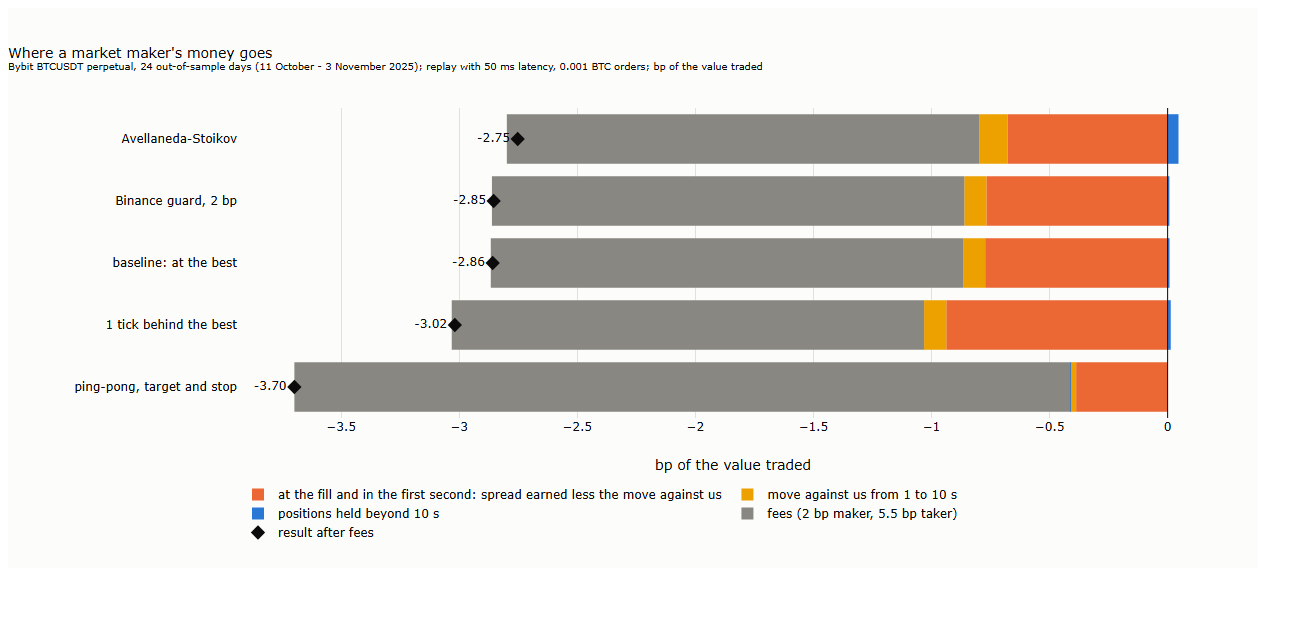

design,spread,first second,1 to 10 s,beyond 10 s,before fees,fees,after fees,fills
str,f64,f64,f64,f64,f64,f64,f64,i64
"""baseline""",-0.033,-0.74,-0.093,0.008,-0.858,-2.0,-2.86,1591781
"""guard_2""",-0.032,-0.735,-0.094,0.007,-0.854,-2.0,-2.85,1579893
"""as_5_2""",0.717,-1.396,-0.119,0.046,-0.752,-2.0,-2.75,143788
"""behind_1""",-0.034,-0.903,-0.094,0.013,-1.018,-2.0,-3.02,1271777
"""pp_e0_c110_n2""",0.037,-0.425,-0.023,-0.002,-0.412,-3.29,-3.7,1279871


In [3]:
run("l24_key_chart.py")
pictures("24_key")
K = result("key.json")
display(pl.DataFrame([(d, round(K[d]["spread_bp"], 3), round(K[d]["move_1s_bp"], 3), round(K[d]["move_10s_bp"], 3), round(K[d]["positions_bp"], 3), round(K[d]["result_bp"], 3),
                       round(K[d]["fees_bp"], 2), round(K[d]["after_fee_bp"], 2), K[d]["fills"]) for d in K],
                     schema=["design", "spread", "first second", "1 to 10 s", "beyond 10 s", "before fees", "fees", "after fees", "fills"], orient="row"))

## 2. A quoting rule as a family of choices

Every design is a class with two methods: `slots`, which returns the orders the design wants at the current book update, and `stop`, which returns the next exit at market, if any. A design such as the guard or the kill switch only changes the prices of the baseline's slots; the wrappers `Kill`, `Stop` and `Pause` add a choice to any design. The baseline and the pause read in full:

In [4]:
import inspect, l24_designs as G
print(inspect.getsource(G.Quoter)); print(inspect.getsource(G.Pause))
print("variants on the sampled hours, fixed before the tests:", 1 + 4 + 4 + len(G.grid_as()) + len(G.grid_pingpong()),
      "| added after the tests: stops", len(G.grid_stop_all()), "depth", len(G.grid_depth()), "pause", len(G.grid_pause()))

class Quoter:
    """The baseline (theta=None, k=0), the Binance guard (theta in bp) and quoting k ticks behind the best (H1, H3)."""

    def __init__(self, theta=None, k=0):
        self.theta, self.k = theta, k; self.name = "baseline" if theta is None and k == 0 else (f"guard_{theta:g}" if theta is not None else f"behind_{k}")

    def slots(self, st, A, i):
        q = st.pos; out = {}
        def side(s):
            def fn(a, b):
                p = A.bid[a:b] - self.k if s == 1 else A.ask[a:b] + self.k
                if self.theta is not None: p = np.where(s * A.gap[a:b] <= -self.theta, np.nan, p)
                return p
            return fn
        if q < LIMIT: out[("e", 1)] = (1, side(1), "entry", None)
        if q > -LIMIT: out[("e", -1)] = (-1, side(-1), "entry", None)
        return out

    def stop(self, st, A, i, r):
        return None

class Pause:
    """A design that, after a fill on one side, posts no new entry quote on that side for `ms` (hypotheses.md, 2026-1

## 3. The designs

`l24_s3_charts.py` draws the two figures of §3 from the summaries of the sampled hours: all variants after fees (`l24_after_fees.py`), the stops (`l24_stops.py`), the pause (`l24_pause.py`), the latency runs (`l24_latency.py`), the Binance diagnostic (`l24_speed_check.py`) and the deeper quotes (`l24_depth.py`). With `RUN_CHECK` the cell first replays CHECK_DAY's four sampled hours for the baseline and Avellaneda-Stoikov and compares them with the shipped results.

l24_s3_charts.py : 5 s


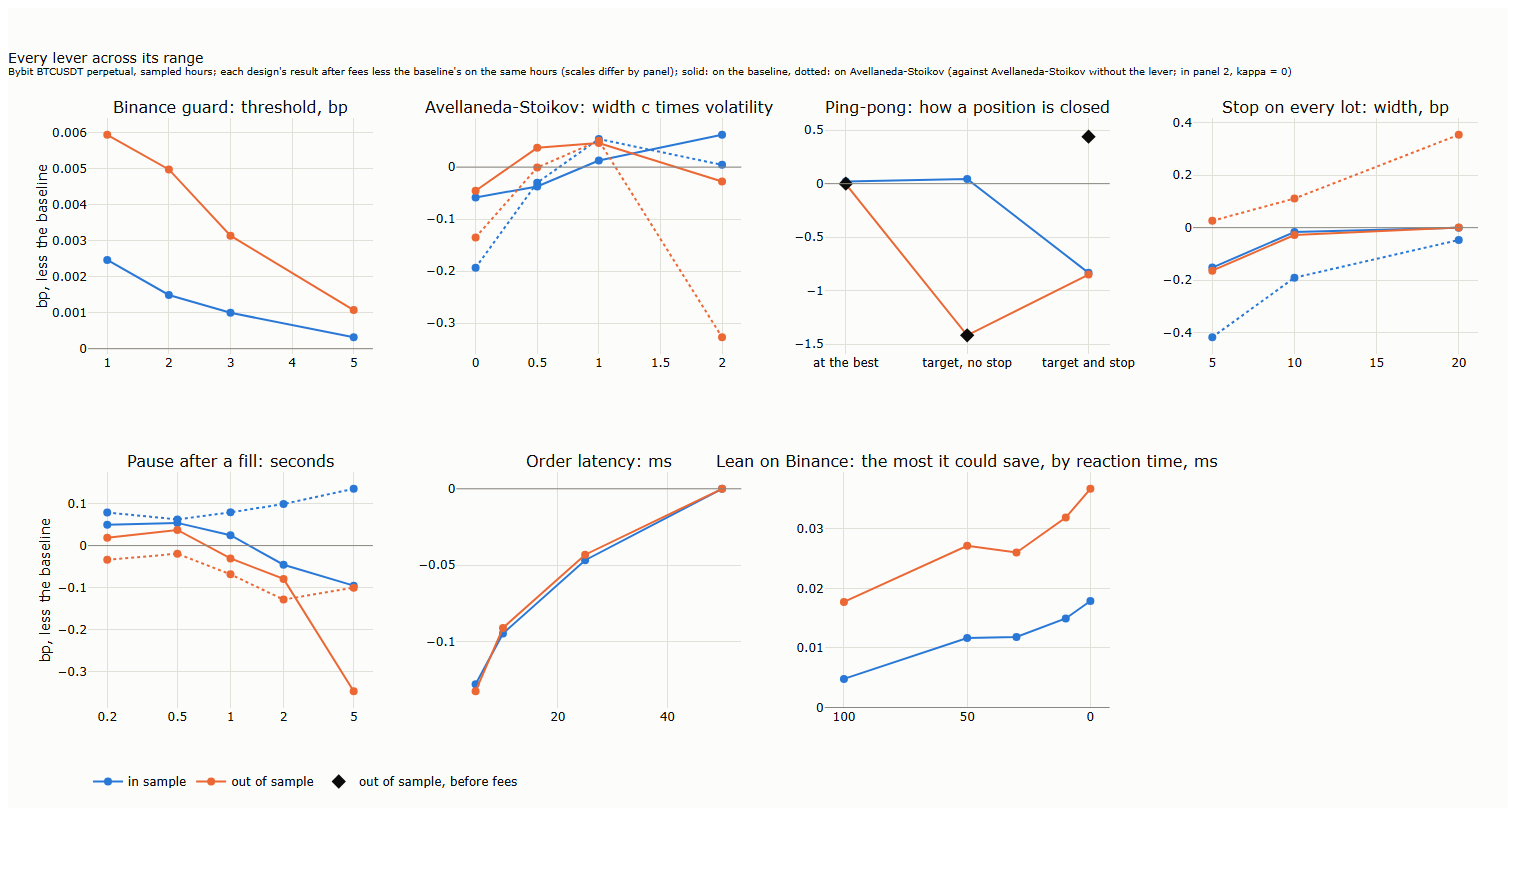

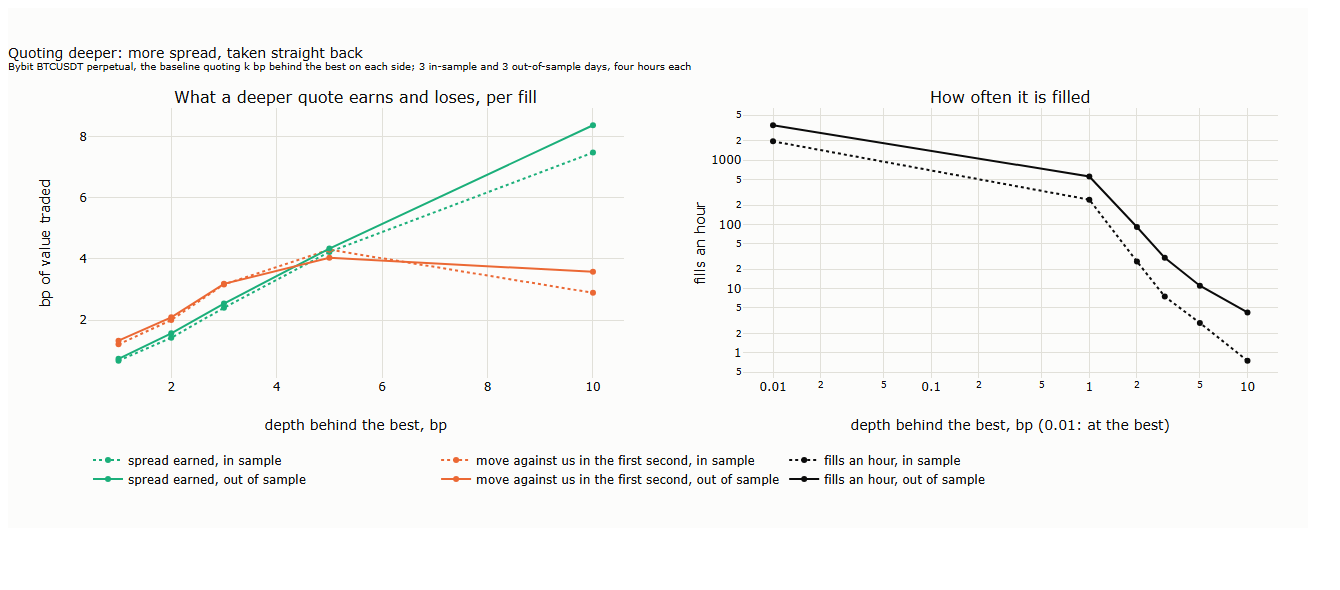

design,"before fees, in","before fees, out","after fees, out","fills an hour, out",taker share of value
str,f64,f64,f64,i64,f64
"""behind_110""",-0.51,-0.71,-2.71,441,0.0
"""as_0_1""",-0.758,-0.8,-2.8,614,0.0
"""as_5_1""",-0.799,-0.804,-2.804,704,0.0
"""as_5_0.5""",-0.849,-0.814,-2.814,1460,0.0
"""as_2_1""",-0.789,-0.819,-2.819,680,0.0
"""as_1_1""",-0.769,-0.827,-2.827,657,0.0
"""as_2_0.5""",-0.856,-0.835,-2.835,1429,0.0
"""as_0.5_1""",-0.753,-0.836,-2.836,636,0.0
"""as_1_0.5""",-0.857,-0.844,-2.844,1387,0.0


design,"after fees, in","after fees, out",stops,share of stops the mid came back after
str,f64,f64,i64,f64
"""as_5_2""",-2.629,-3.199,0,NaN
"""as_5_2_stop10""",-2.82,-3.089,492,0.45
"""as_5_2_stop10_h5""",-2.819,-3.025,374,0.47
"""as_5_2_stop20""",-2.676,-2.846,138,0.55
"""as_5_2_stop20_h5""",-2.677,-2.933,107,0.51
"""as_5_2_stop5""",-3.046,-3.173,1152,0.49
"""as_5_2_stop5_h5""",-3.025,-3.233,929,0.49
"""as_5_2_stopk2""",-2.884,-3.095,406,0.45
"""as_5_2_stopk2_h5""",-2.822,-3.033,310,0.44


In [5]:
if RUN_CHECK:
    run("l24_run.py", "--sample", "--tag=check", "--designs=baseline,as_5_2", CHECK_DAY)
    a, b = json.loads((SHIPPED / "sample_days" / f"{CHECK_DAY}.json").read_text()), result(f"sample_days_check/{CHECK_DAY}.json")
    display(pl.DataFrame([(k, m, a[k][m], b[k][m]) for k in ("baseline", "as_5_2") for m in ("fills", "result_bp", "mk10")], schema=["design", "measure", "shipped", "recomputed"], orient="row"))
run("l24_s3_charts.py")
pictures("24_s3_levers", "24_s3_depth")
AF = result("after_fees.json")
display(pl.DataFrame([(k, round(v["in"]["before_bp"], 3), round(v["oos"]["before_bp"], 3), round(v["oos"]["after_bp"], 3), round(v["oos"]["fills_hour"]), round(v["oos"]["taker_value_share"], 3))
                      for k, v in sorted(AF.items(), key=lambda kv: -kv[1]["oos"]["after_bp"])][:15],
                     schema=["design", "before fees, in", "before fees, out", "after fees, out", "fills an hour, out", "taker share of value"], orient="row"))
S = result("stops.json")["designs"]
display(pl.DataFrame([(k, round(v["in"]["after_bp"], 3), round(v["oos"]["after_bp"], 3), v["in"]["stops"] + v["oos"]["stops"], round(v.get("after_stop", {}).get("share_back", float("nan")), 2))
                      for k, v in sorted(S.items())], schema=["design", "after fees, in", "after fees, out", "stops", "share of stops the mid came back after"], orient="row"))

## 4. Tests

`l24_tests.py` pools the fills of the 24 out-of-sample days per design, bootstraps over days and corrects the four p-values together (results/tests.json); `l24_drivers.py` splits each design's fills into first and follow-up fills and stops (results/drivers.json); `l24_s4_chart.py` draws the figure.

l24_s4_chart.py : 4 s


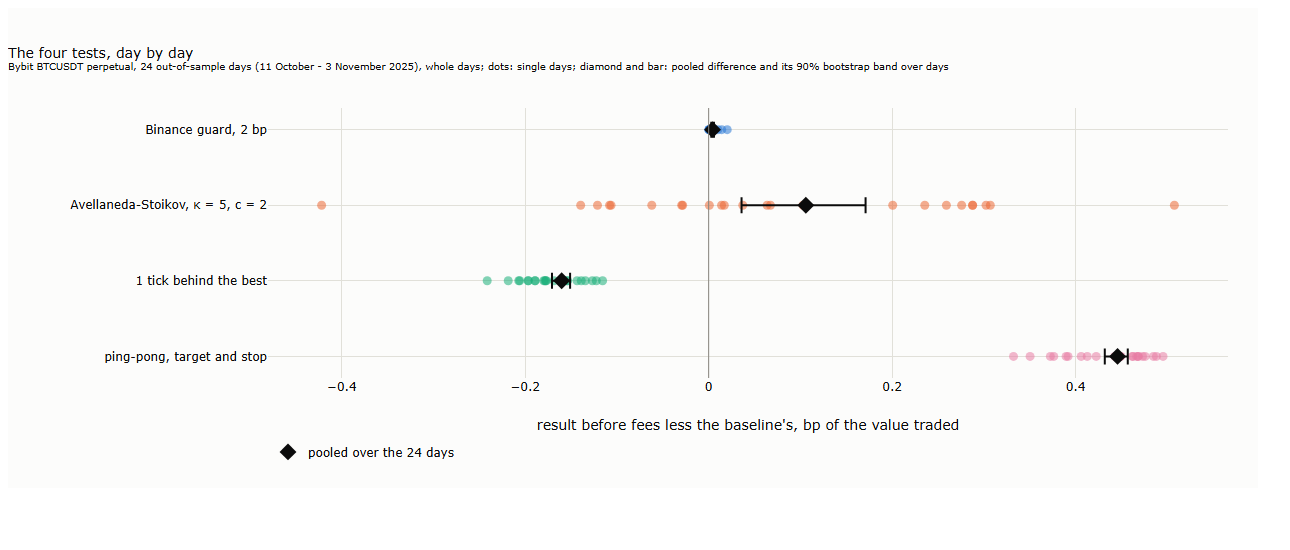

test,design,"better by, bp",band low,band high,days better,p,holds after BH
str,str,f64,f64,f64,i64,f64,bool
"""H1""","""guard_2""",0.004,0.003,0.006,24,0.0005,true
"""H2""","""as_5_2""",0.106,0.036,0.171,16,0.0035,true
"""H3""","""behind_1""",-0.16,-0.171,-0.151,0,1.0,false
"""H4""","""pp_e0_c110_n2""",0.446,0.432,0.457,24,0.0005,true
"""H2 before correction""","""as_5_1""",0.085,0.059,0.111,18,0.0005,null


design,"before fees, bp","after fees, USDT a day",fills an hour,"value traded, USDT a day"
str,f64,i64,i64,i64
"""as_5_1""",-0.773,-553,751,1992851
"""as_5_2""",-0.752,-182,250,663003
"""baseline""",-0.858,-2093,2764,7324031
"""behind_1""",-1.018,-1766,2208,5850031
"""guard_2""",-0.854,-2074,2743,7269542
"""pp_e0_c110_n2""",-0.412,-2178,2222,5890680


design,follow-up share,"1 s, first fills","1 s, follow-ups",stop share,"1 s, stops"
str,f64,f64,f64,f64,f64
"""baseline""",0.581,-0.631,-0.874,0.0,NaN
"""behind_1""",0.592,-0.9,-0.962,0.0,NaN
"""as_5_2""",0.247,-0.6,-0.919,0.0,NaN
"""guard_2""",0.577,-0.632,-0.866,0.0,NaN
"""pp_e0_c110_n2""",0.55,-0.633,-0.873,0.367,0.263


In [6]:
run("l24_s4_chart.py")
pictures("24_s4_tests")
T = result("tests.json")
display(pl.DataFrame([(h, t["design"], round(t["diff_bp"], 3), round(t["ci90"][0], 3), round(t["ci90"][1], 3), t["days_above"], round(t["p"], 4), t["bh_holds"]) for h, t in T["tests"].items()],
                     schema=["test", "design", "better by, bp", "band low", "band high", "days better", "p", "holds after BH"], orient="row"))
display(pl.DataFrame([(k, round(v["result_bp"], 3), round(v["after_fee_usdt_day"]), round(v["fills_hour"]), round(v["value_usdt_day"])) for k, v in T["designs"].items()],
                     schema=["design", "before fees, bp", "after fees, USDT a day", "fills an hour", "value traded, USDT a day"], orient="row"))
Dr = result("drivers.json")
display(pl.DataFrame([(k, round(v["follow_share"], 3), round(v["resting_first"], 3), round(v["resting_follow"], 3), round(v["by_role"].get("stop", {}).get("share", 0), 3),
                       round(v["by_role"].get("stop", {}).get("m1_bp", float("nan")), 3)) for k, v in Dr.items()],
                     schema=["design", "follow-up share", "1 s, first fills", "1 s, follow-ups", "stop share", "1 s, stops"], orient="row"))

## 5. 10 October 2025

`l24_oct10.py` and `l24_case.py` replay 20:30 to 23:00 UTC for the 25 designs of the case study; `l24_oct10_phases.py` fixes the phases from the mid and splits each design's result (results/oct10_phases.json, with the paths and fills per minute that the figures need); `l24_oct10_charts.py` draws both figures.

l24_oct10_charts.py : 5 s


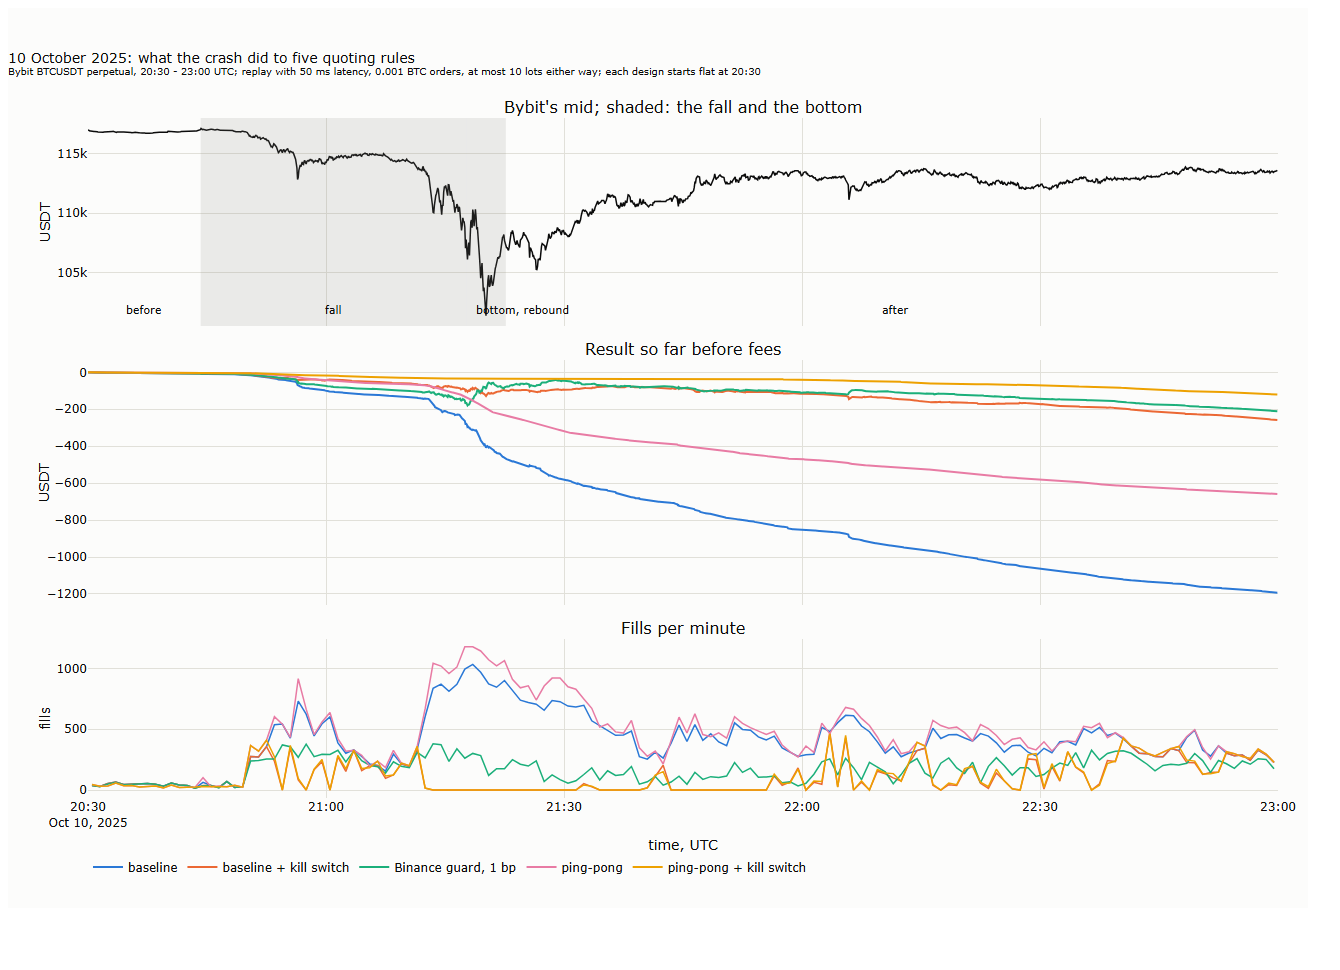

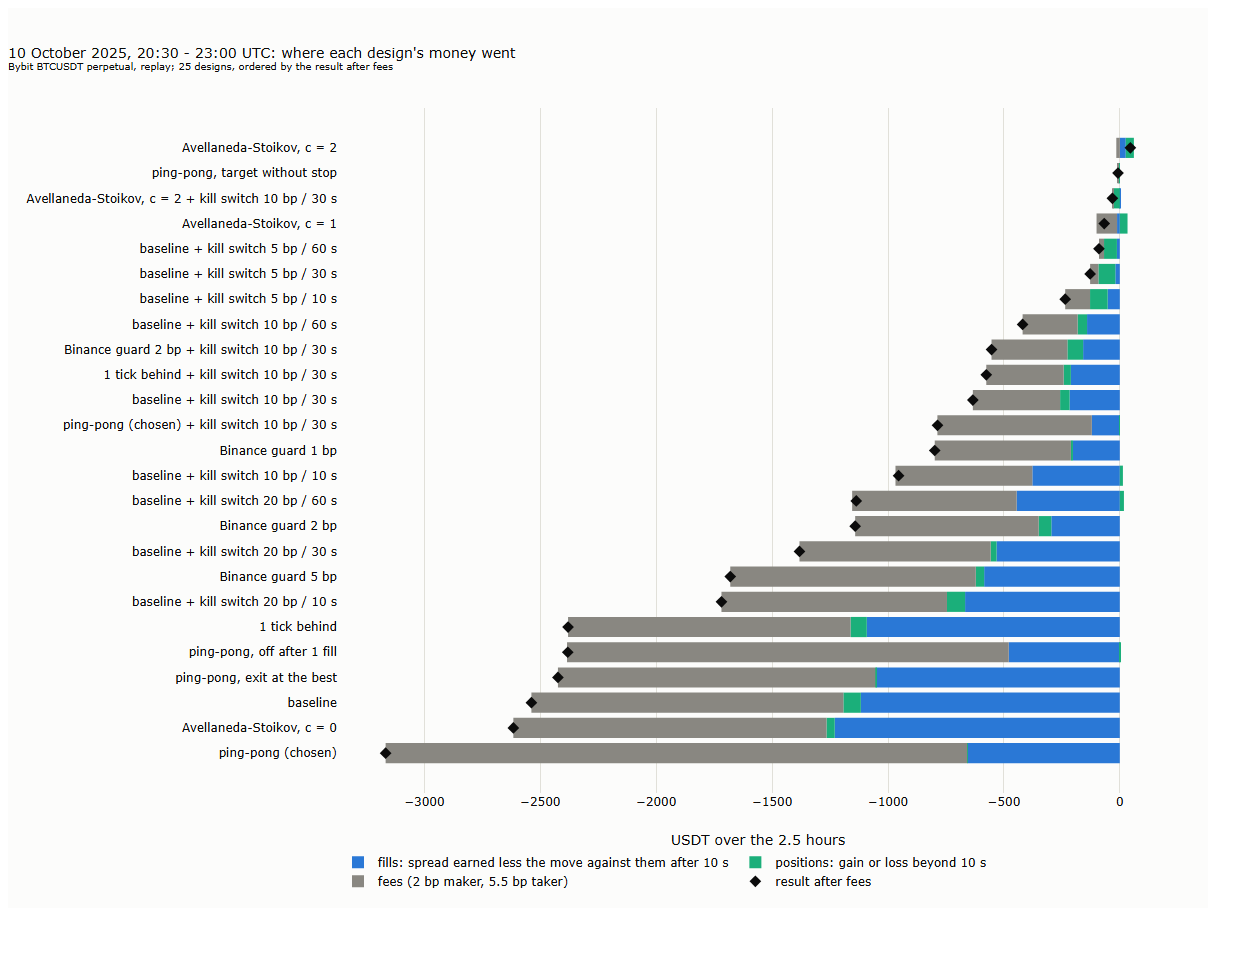

phases: before 20:30:00-20:44:12 | fall 20:44:12-21:17:40 | bottom 21:17:40-21:22:40 | rebound 21:22:40-21:23:32 | after 21:23:32-23:00:00 | fall -1290 bp


design,"after fees, USDT",before fees,fills after 10 s,positions,fees,fills
str,f64,f64,f64,f64,f64,i64
"""as_5_2""",45.5,60.7,25.7,35.0,-15.2,674
"""pp_e0_b110_n2""",-7.8,-6.8,0.1,-6.9,-1.0,42
"""as_5_2_kill""",-32.0,-26.6,1.0,-27.5,-5.5,237
"""as_5_1""",-67.1,21.4,-11.9,33.3,-88.5,3947
"""baseline_kill_5_60""",-89.9,-68.1,-12.4,-55.6,-21.9,942
"""baseline_kill_5_30""",-128.1,-92.4,-19.4,-73.0,-35.7,1551
"""baseline_kill_5_10""",-235.6,-128.4,-52.4,-76.0,-107.2,4701
"""baseline_kill_10_60""",-419.3,-182.0,-141.3,-40.7,-237.3,10408
"""guard_2_kill""",-553.4,-226.1,-158.3,-67.8,-327.3,14374


In [7]:
run("l24_oct10_charts.py")
pictures("24_s5_crash", "24_s5_split")
O = result("oct10_phases.json")
from datetime import datetime, timezone
print("phases:", " | ".join(f"{n} {datetime.fromtimestamp(a / 1000, tz=timezone.utc):%H:%M:%S}-{datetime.fromtimestamp(b / 1000, tz=timezone.utc):%H:%M:%S}" for n, a, b in O["phases"]),
      f"| fall {O['fall_bp']:.0f} bp")
display(pl.DataFrame([(d, round(v["total"]["after_fee"], 1), round(v["total"]["result"], 1), round(v["total"]["kept_10s"], 1), round(v["total"]["positions"], 1), round(v["total"]["fees"], 1), v["total"]["fills"])
                      for d, v in sorted(O["designs"].items(), key=lambda kv: -kv[1]["total"]["after_fee"])],
                     schema=["design", "after fees, USDT", "before fees", "fills after 10 s", "positions", "fees", "fills"], orient="row"))

## 6. What it takes to break even

`l24_s6_chart.py` puts the tested designs at each of Bybit's public fee levels (results/sources.md) and ranks what each advantage is worth.

l24_s6_chart.py : 4 s


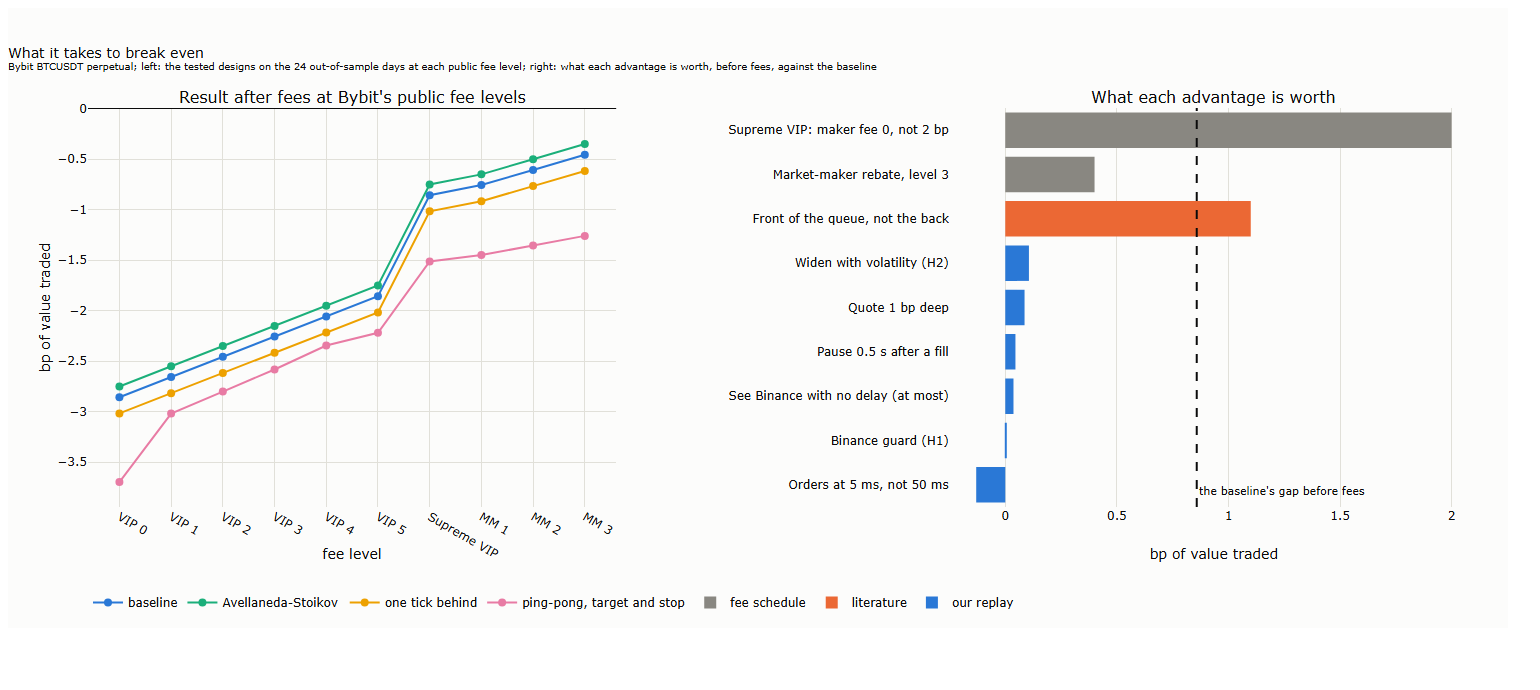

design,VIP 0,VIP 5,Supreme VIP,MM 3
str,f64,f64,f64,f64
"""as_5_1""",-2.77,-1.77,-0.77,-0.37
"""as_5_2""",-2.75,-1.75,-0.75,-0.35
"""baseline""",-2.86,-1.86,-0.86,-0.46
"""behind_1""",-3.02,-2.02,-1.02,-0.62
"""guard_2""",-2.85,-1.85,-0.85,-0.45
"""pp_e0_c110_n2""",-3.7,-2.22,-1.51,-1.26


In [8]:
run("l24_s6_chart.py")
pictures("24_s6_breakeven")
TIERS = [("VIP 0", 2.0, 5.5), ("VIP 5", 1.0, 3.2), ("Supreme VIP", 0.0, 3.0), ("MM 3", -0.4, 3.0)]
display(pl.DataFrame([(k, *[round(v["result_bp"] - (1 - v["taker_value_share"]) * m - v["taker_value_share"] * t, 2) for _, m, t in TIERS]) for k, v in T["designs"].items()],
                     schema=["design"] + [n for n, _, _ in TIERS], orient="row"))

## 7. Where market making pays

For a trader who wants the position anyway: a filled resting order costs the maker fee plus the move against it in the first second; a market order of the same small size costs the taker fee plus half a spread of one tick and a slippage of thousandths of a basis point (Lecture 21, §3.2).

In [9]:
m1 = -Dr["baseline"]["m1_bp"]; resting, market = 2.0 + m1, 5.5 + 0.005
print(f"resting order: 2 bp + {m1:.2f} bp = {resting:.2f} bp | market order: about {market:.2f} bp | saved: {market - resting:.2f} bp per trade")

resting order: 2 bp + 0.77 bp = 2.77 bp | market order: about 5.50 bp | saved: 2.73 bp per trade


## 8. A test of your own: your fee level

Which of the 85 variants of the sampled hours does best at the fee level you could reach? Change `MAKER` and `TAKER` (bp) and rerun. Exercise: at what taker fee, with your maker fee, would ping-pong's stops start to pay?

In [10]:
MAKER, TAKER = 1.0, 3.2                                                    # VIP 5 on Bybit's public schedule
rows = [(k, v["oos"]["before_bp"] - (1 - v["oos"]["taker_value_share"]) * MAKER - v["oos"]["taker_value_share"] * TAKER, v["oos"]["fills_hour"]) for k, v in AF.items()]
display(pl.DataFrame(rows, schema=["design", "after your fees, bp, out of sample", "fills an hour"], orient="row").sort("after your fees, bp, out of sample", descending=True).head(10))

design,"after your fees, bp, out of sample",fills an hour
str,f64,f64
"""behind_110""",-1.710363,440.916667
"""as_0_1""",-1.799951,614.375
"""as_5_1""",-1.80443,703.541667
"""as_5_0.5""",-1.813743,1460.458333
"""as_2_1""",-1.818811,680.291667
"""as_1_1""",-1.826942,656.958333
"""as_2_0.5""",-1.834818,1428.875
"""as_0.5_1""",-1.836112,635.958333
"""as_1_0.5""",-1.843976,1387.0
